# 03 - Late-delivery risk

Story notebook for Q2. All logic is in `src/sca/risk_model.py` and `src/sca/risk_report.py`. Run `python -m sca ingest` first. Numbers here match `reports/risk_model_results.md`.

In [1]:
import os
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(root)

from sca import risk_model as rm
from sca import risk_report as rr
from sca.config import load_config, run_paths
from sca.ingest import read_processed

cfg = load_config()
paths = run_paths(cfg)
tables = read_processed(paths.processed_dir)
orders = rm.build_orders(tables)
print(
    f"{len(orders):,} valid orders, {orders[rm.TARGET].mean():.1%} late, "
    f"{orders['order_ts'].min():%Y-%m-%d} to {orders['order_ts'].max():%Y-%m-%d}"
)

62,897 valid orders, 57.3% late, 2015-01-01 to 2018-01-31


## Leakage guard

Only information known when an order is placed may be a feature.

In [2]:
print("Forbidden (post-shipping) columns:", sorted(rm.FORBIDDEN_COLUMNS))
print("Model features:", rm.FEATURES)
rm.assert_no_leakage(rm.feature_matrix(orders).columns)  # raises LeakageError if anything slipped in
print("No forbidden column reaches the feature matrix.")

Forbidden (post-shipping) columns: ['cost_amount', 'delivery_status', 'is_late', 'late_delivery_risk', 'order_status', 'profit', 'profit_per_unit', 'profit_ratio', 'ship_date', 'ship_date_key', 'ship_ts', 'shipping_days_real', 'shipping_delay_days']
Model features: ['shipping_mode', 'market', 'region', 'country', 'segment', 'payment_type', 'customer_country', 'dominant_category', 'dominant_department', 'scheduled_days', 'n_items', 'total_quantity', 'total_gross_sales', 'max_discount_rate', 'mean_discount_rate', 'max_unit_price', 'n_categories', 'order_dow', 'order_hour', 'order_month']
No forbidden column reaches the feature matrix.


## Time-based split

Train on earlier orders, test on the most recent 20%. No random splits.

In [3]:
split = rm.time_split(orders, cfg.risk.test_fraction, cfg.risk.val_fraction)
pd.DataFrame(
    {
        k: {
            "orders": len(v),
            "from": v["order_ts"].min().date(),
            "to": v["order_ts"].max().date(),
            "late rate": round(v[rm.TARGET].mean(), 3),
        }
        for k, v in split.items()
    }
).T

,orders,from,to,late rate
train,42770,2015-01-01,2017-02-21,0.573
val,7548,2017-02-21,2017-07-10,0.569
test,12579,2017-07-10,2018-01-31,0.574


## Train and evaluate

Shipping-mode-only baseline, logistic regression and LightGBM.

In [4]:
run = rm.train(orders, cfg.risk, cfg.seed)
champ = rm.champion(run)
summary = rr.write_outputs(run, paths, cfg.seed, sample=False)  # charts, tables and report
pd.DataFrame(run.metrics).T[["roc_auc", "pr_auc", "brier", "threshold", "precision", "recall"]].round(3)

F:\SupplyPulse\.venv\Lib\site-packages\shap\explainers\_tree.py:620: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


,roc_auc,pr_auc,brier,threshold,precision,recall
shipping_mode_only,0.744,0.786,0.188,0.463,0.839,0.589
logistic,0.752,0.840,0.190,0.476,0.880,0.555
lightgbm,0.778,0.859,0.175,0.608,0.897,0.589


## Charts

**Champion (validation PR-AUC): lightgbm.** Leakage alarm: False

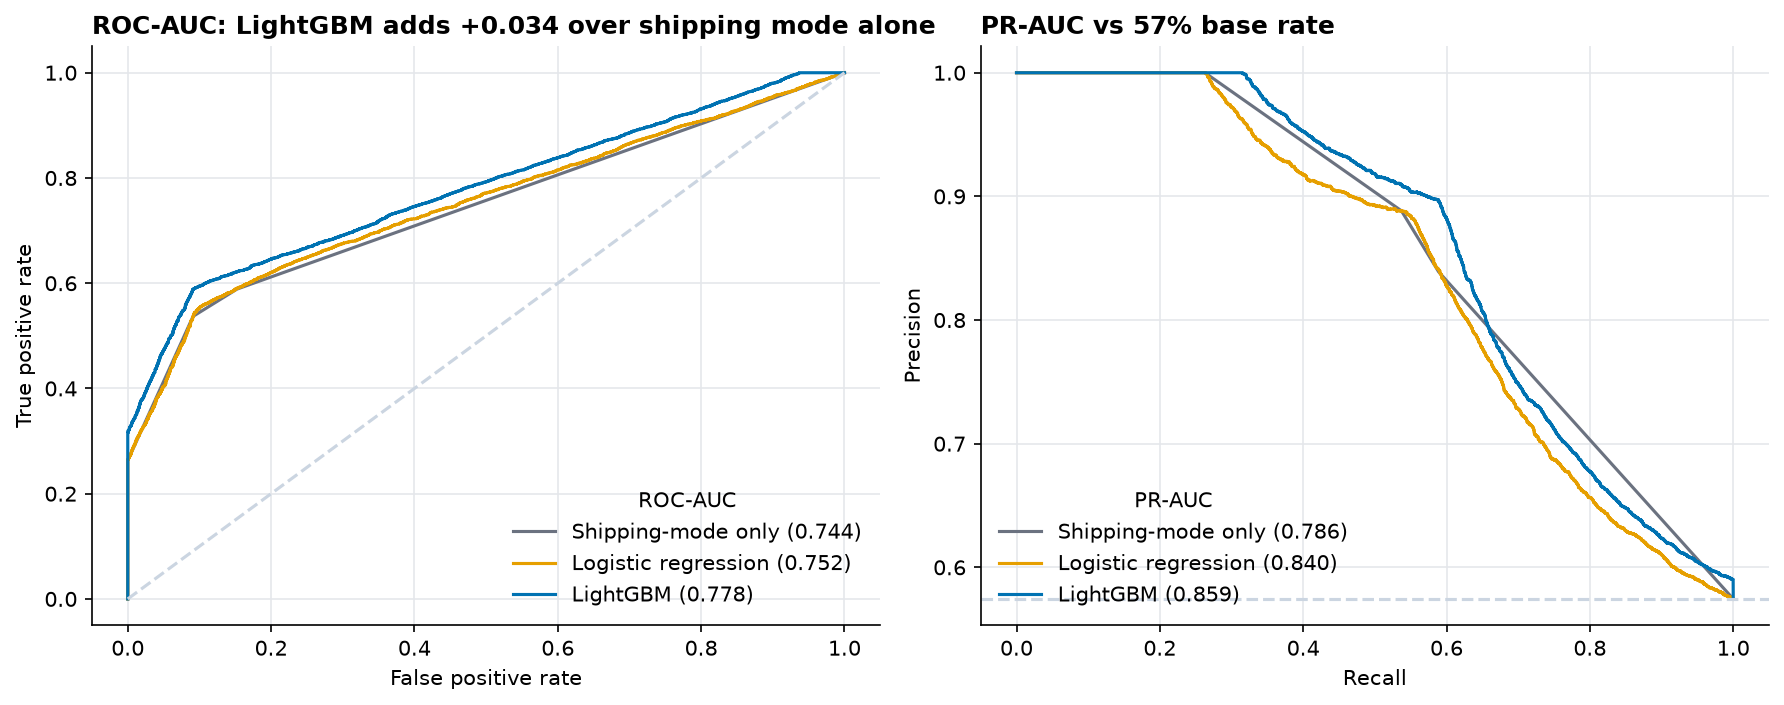

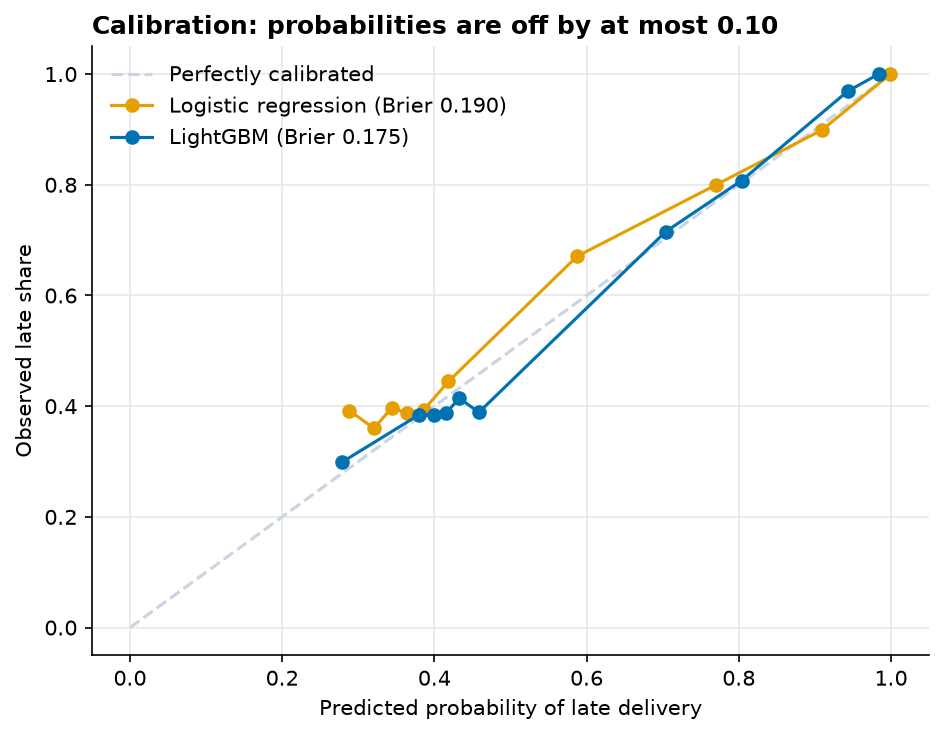

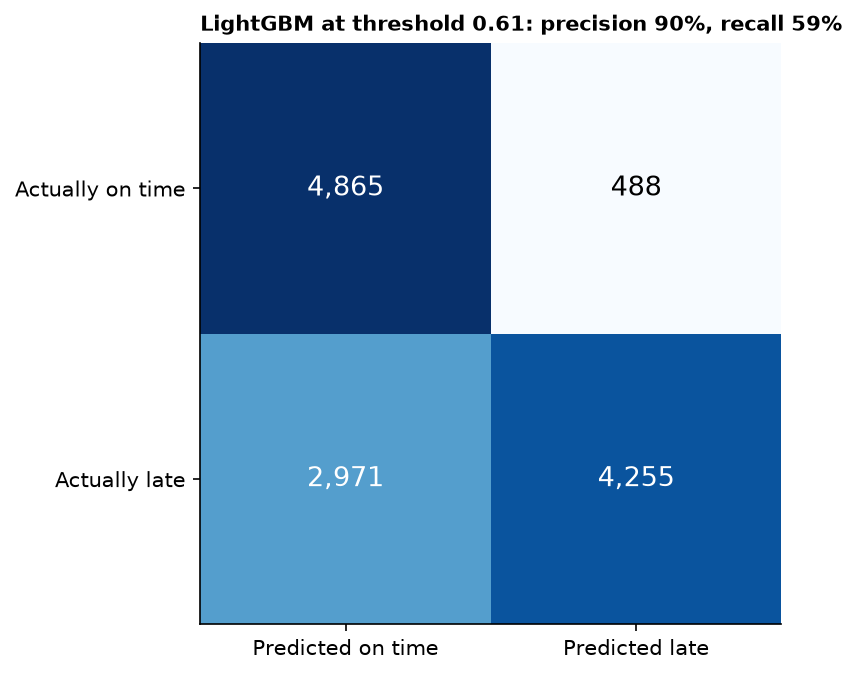

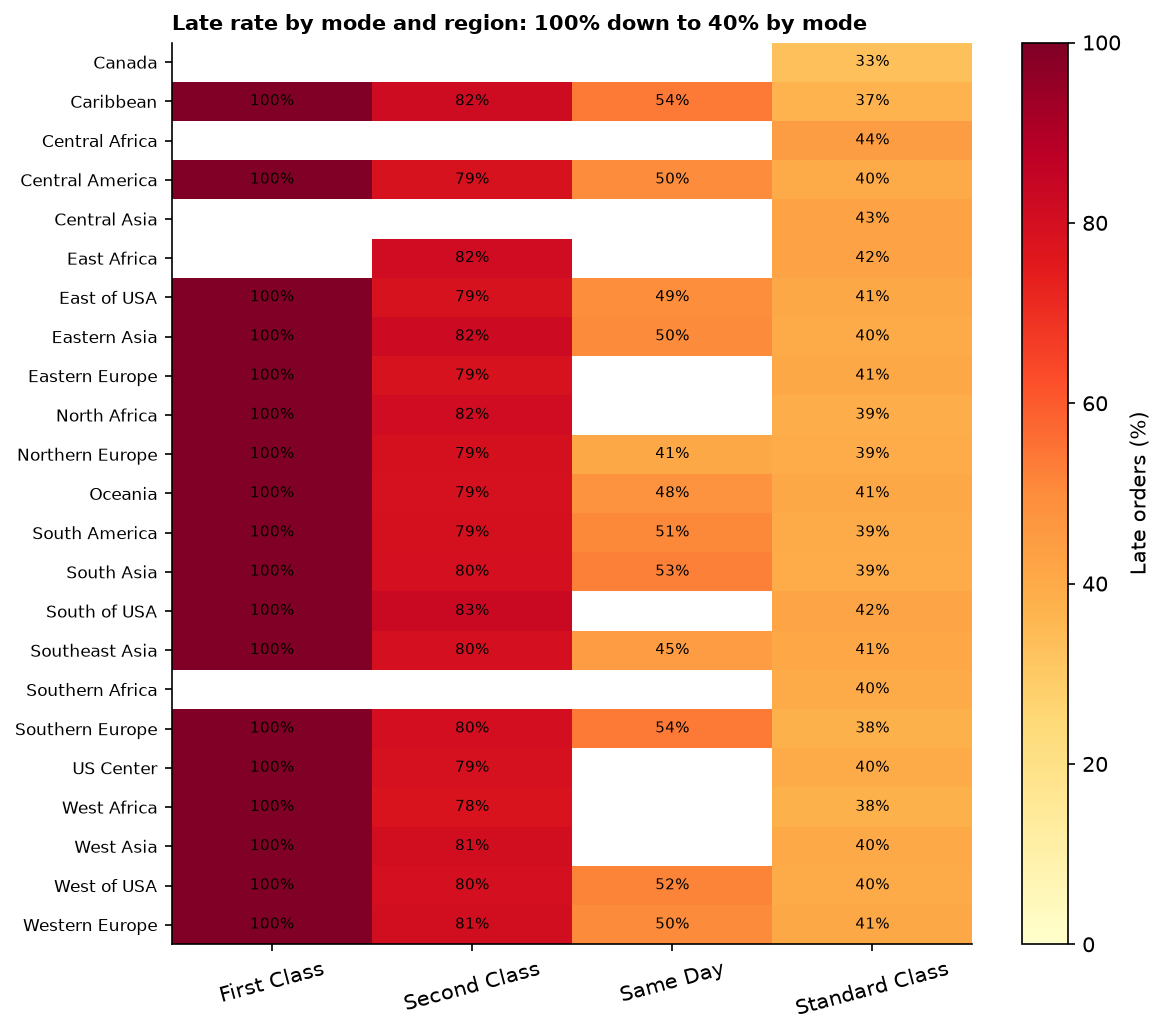

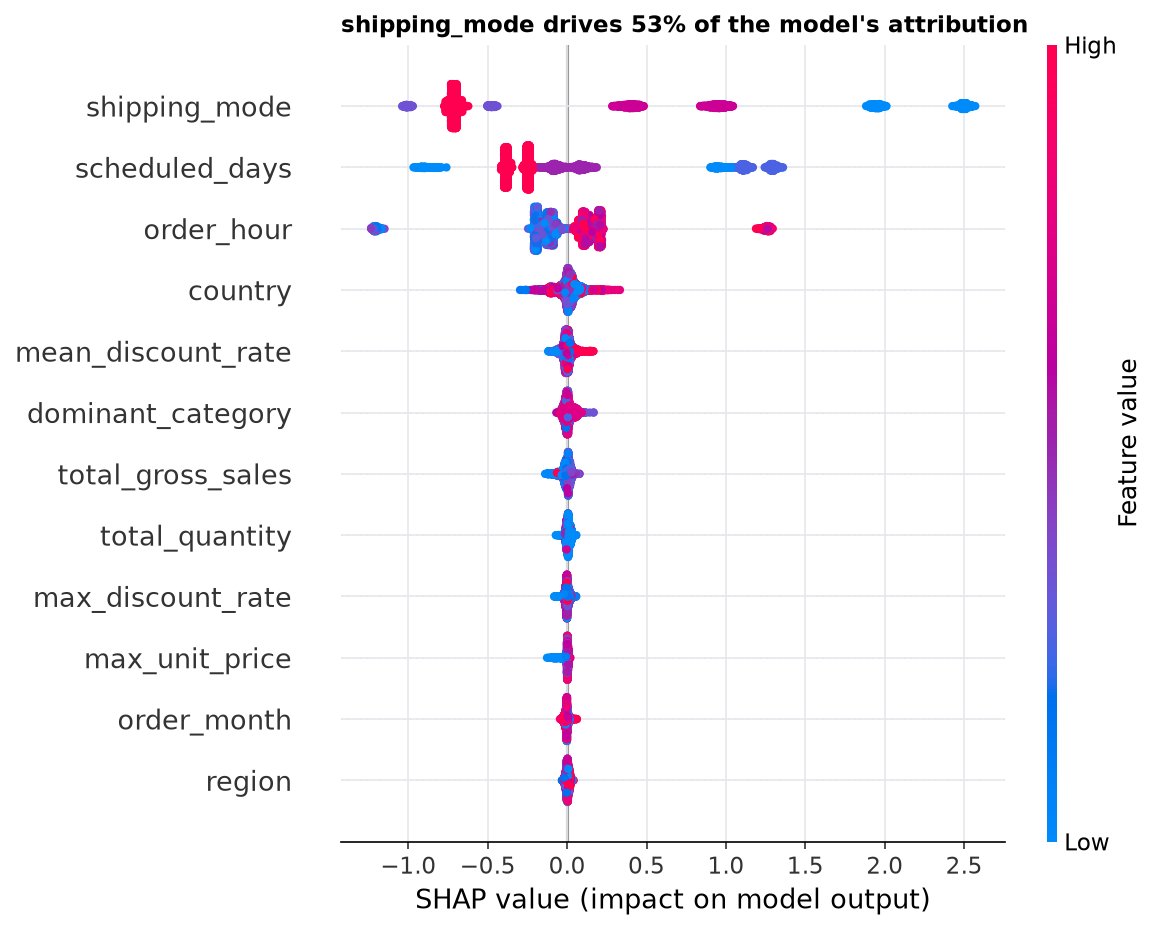

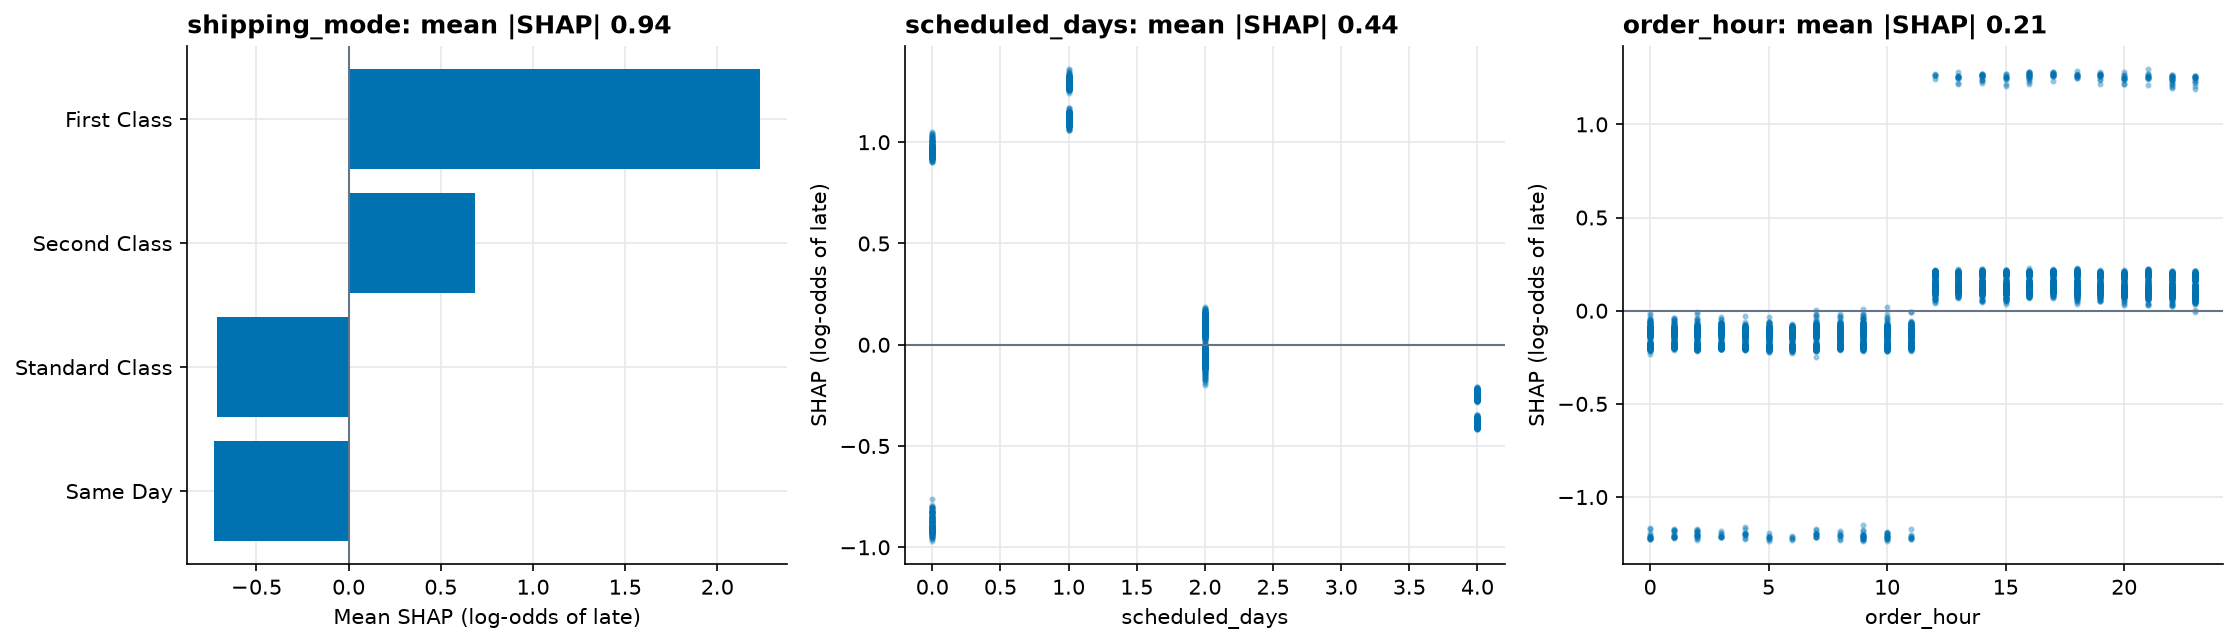

In [5]:
display(Markdown(f"**Champion (validation PR-AUC): {champ}.** Leakage alarm: {rm.leakage_alarm(run)}"))
for fig in (
    "risk_01_roc_pr",
    "risk_02_calibration",
    "risk_03_confusion",
    "risk_06_drivers",
    "risk_04_shap_summary",
    "risk_05_shap_dependence",
):
    display(Image(paths.figures_dir / f"{fig}.png"))

## Threshold choice and drivers

In [6]:
report = (paths.reports_dir / "risk_model_results.md").read_text(encoding="utf-8")
display(Markdown("## Threshold sensitivity" + report.split("### Threshold sensitivity")[1].split("## What drives")[0]))
display(Markdown("## What drives lateness" + report.split("## What drives lateness")[1].split("### SHAP")[0]))

## Threshold sensitivity

The right threshold depends on how much worse a miss is than a false alarm. With a high base rate (57% late), a larger miss cost makes the optimal rule flag almost every order.

| Miss : false-alarm cost | Threshold | Orders flagged | Precision | Recall |
|---|---|---|---|---|
| 1 : 1 | 0.61 | 38% | 89.7% | 58.9% |
| 2 : 1 | 0.32 | 97% | 59.1% | 99.7% |
| 5 : 1 | 0.32 | 97% | 59.1% | 99.7% |

### Ranking the riskiest orders

| Riskiest share of orders | Orders | Late rate | Lift vs base rate |
|---|---|---|---|
| 10% | 1,257 | 100.0% | 1.74x |
| 25% | 3,144 | 94.8% | 1.65x |
| 50% | 6,289 | 77.5% | 1.35x |
| 75% | 9,434 | 64.9% | 1.13x |



## What drives lateness

**Shipping mode alone gets ROC-AUC 0.744; the best model gets 0.778.** Shipping mode therefore accounts for about 88% of the model's lift over chance. Lateness is mostly decided by the shipping mode and its scheduled-days promise, not by who orders or what is ordered.

| Shipping mode | Orders | Late % | Scheduled days |
|---|---|---|---|
| First Class | 9,602 | 100.0% | 1 |
| Second Class | 12,256 | 80.0% | 2 |
| Same Day | 3,407 | 48.4% | 0 |
| Standard Class | 37,632 | 39.8% | 4 |

Within a shipping mode, regions move the late rate by at most 13 pp (cells with at least 100 orders).

![Late rate by mode and region](figures/risk_06_drivers.png)

### Order-time cut-off

**Same Day orders placed before 12:00 are 0% late (1,759 orders); placed from 12:00 on, 100% late (1,648 orders).** Order hour is known at order time, so this is a legitimate feature, and it is why `order_hour` ranks high in the SHAP table. In practice it looks like a noon cut-off that the same-day promise ignores.

